## Simulation output files - excel time plots 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

Import excel files 

In [2]:
# DEfine base direction 
base_dir = os.getcwd()

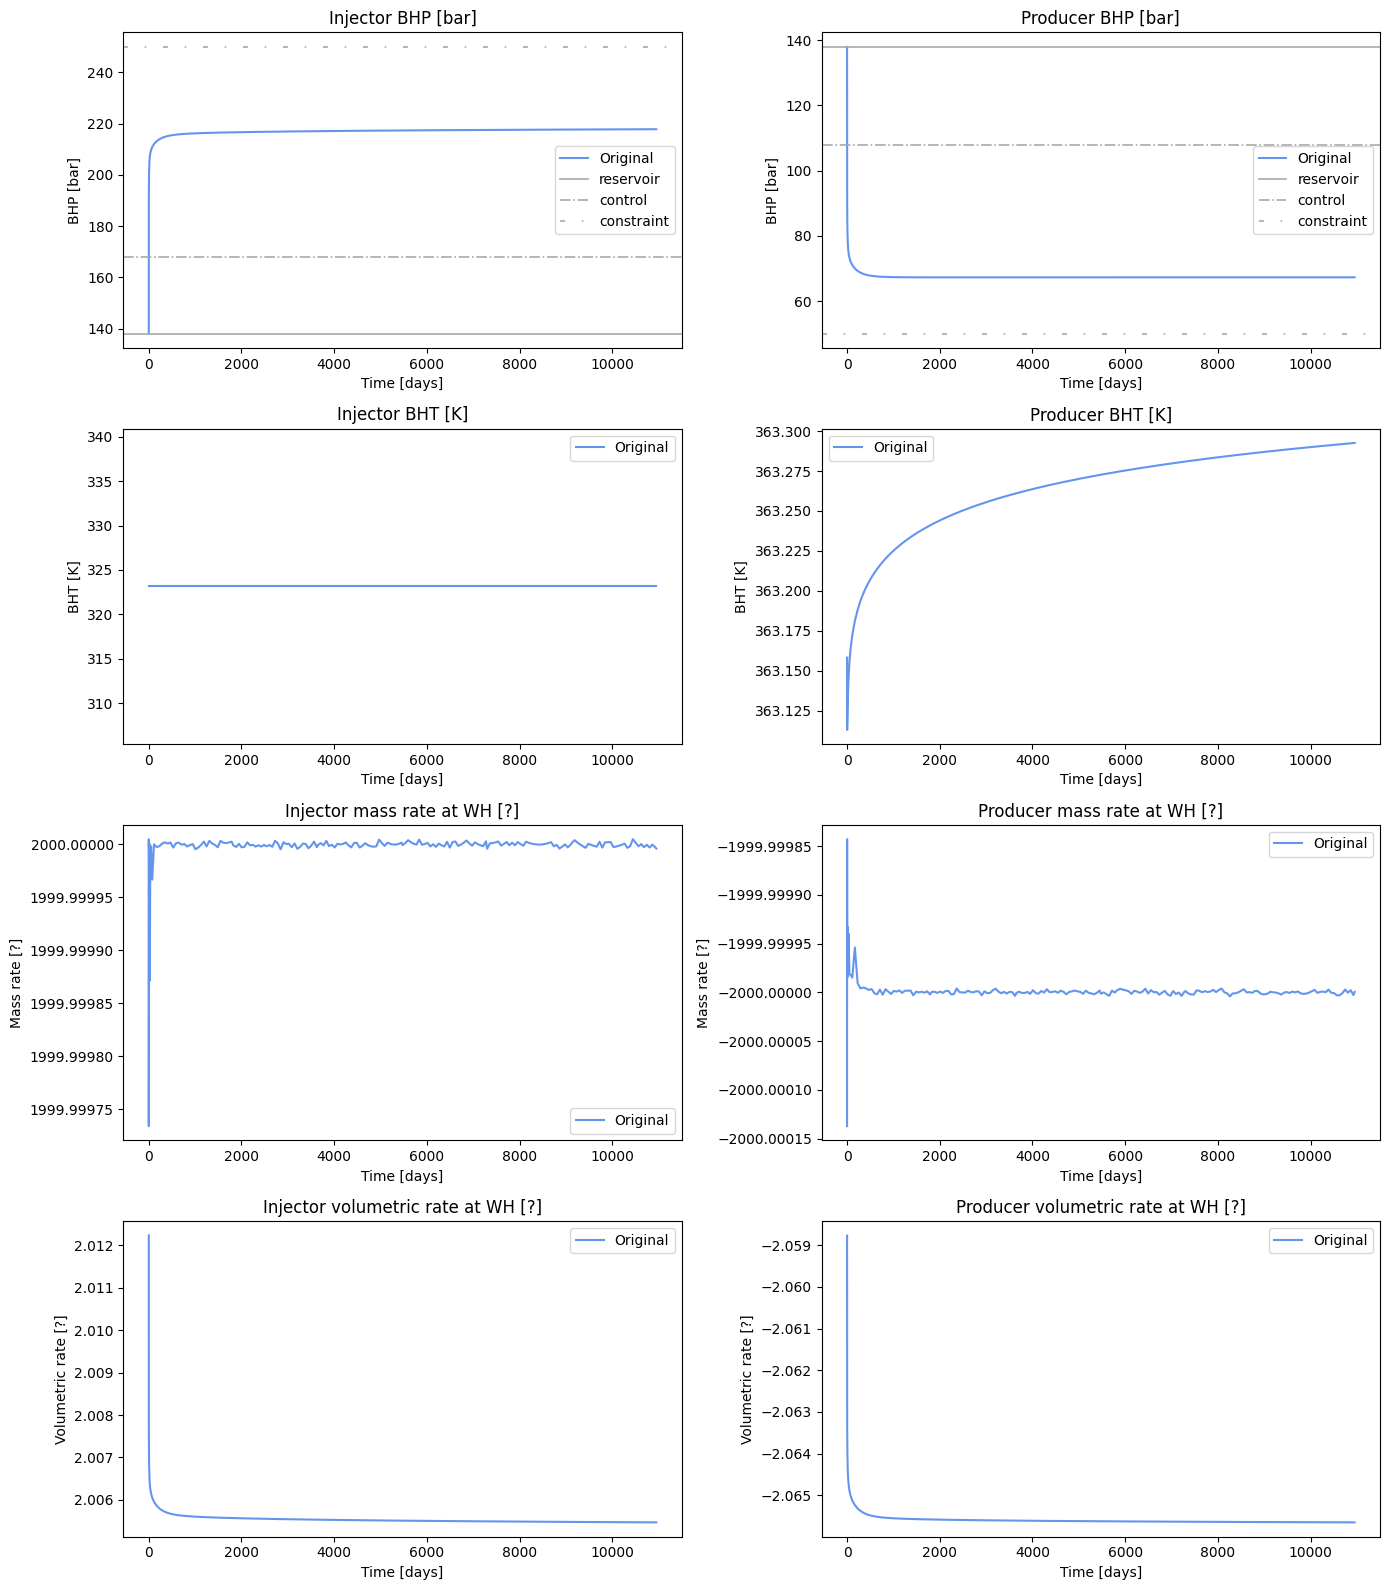

In [ ]:
# Import data 
A1B1C1D1 = os.path.join (base_dir, 'sol_A1B1C1D1_cell_r=2000', 'well_time_data.xlsx')

# Read excel data 
A1B1C1D1  = pd.read_excel(A1B1C1D1)

# Plot results 
plots = [
    ('well_I1_BHP',                     'Injector BHP [bar]',                    'BHP [bar]'),
    ('well_P1_BHP',                     'Producer BHP [bar]',                    'BHP [bar]'),
    ('well_I1_BHT',                     'Injector BHT [K]',                      'BHT [K]'),
    ('well_P1_BHT',                     'Producer BHT [K]',                      'BHT [K]'),
    ('well_I1_mass_rate_L_at_wh',       'Injector mass rate at WH [?]',          'Mass rate [?]'),
    ('well_P1_mass_rate_L_at_wh',       'Producer mass rate at WH [?]',          'Mass rate [?]'),
    ('well_I1_volumetric_rate_L_at_wh', 'Injector volumetric rate at WH [?]',    'Volumetric rate [?]'),
    ('well_P1_volumetric_rate_L_at_wh', 'Producer volumetric rate at WH [?]',    'Volumetric rate [?]'),
]

# Reference lines for the BHP plots: (value [bar], label, linestyle)
loosely_dashdotted = (0, (3, 10, 1, 10))  # (offset, (dash, gap, dot, gap)) in points

ref_lines = {
    'well_I1_BHP': [
        (138, 'reservoir',    '-'),
        (168, 'control',    '-.'),
        (250, 'constraint', loosely_dashdotted),
    ],
    'well_P1_BHP': [
        (138, 'reservoir',    '-'),
        (108, 'control',    '-.'),
        (50,  'constraint', loosely_dashdotted),
    ],
}

plt.rcParams['axes.formatter.useoffset'] = False
fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for ax, (col, title, ylabel) in zip(axes.flatten(), plots):
    ax.plot(A1B1C1D1['time'], A1B1C1D1[col],   color='cornflowerblue', label='Original')

    for value, label, ls in ref_lines.get(col, []):
        ax.axhline(value, color='darkgrey', linestyle=ls, linewidth=1.2, label=label)

    ax.set_title(title)
    ax.set_xlabel('Time [days]')
    ax.set_ylabel(ylabel)
    ax.legend()

plt.tight_layout()
plt.show()

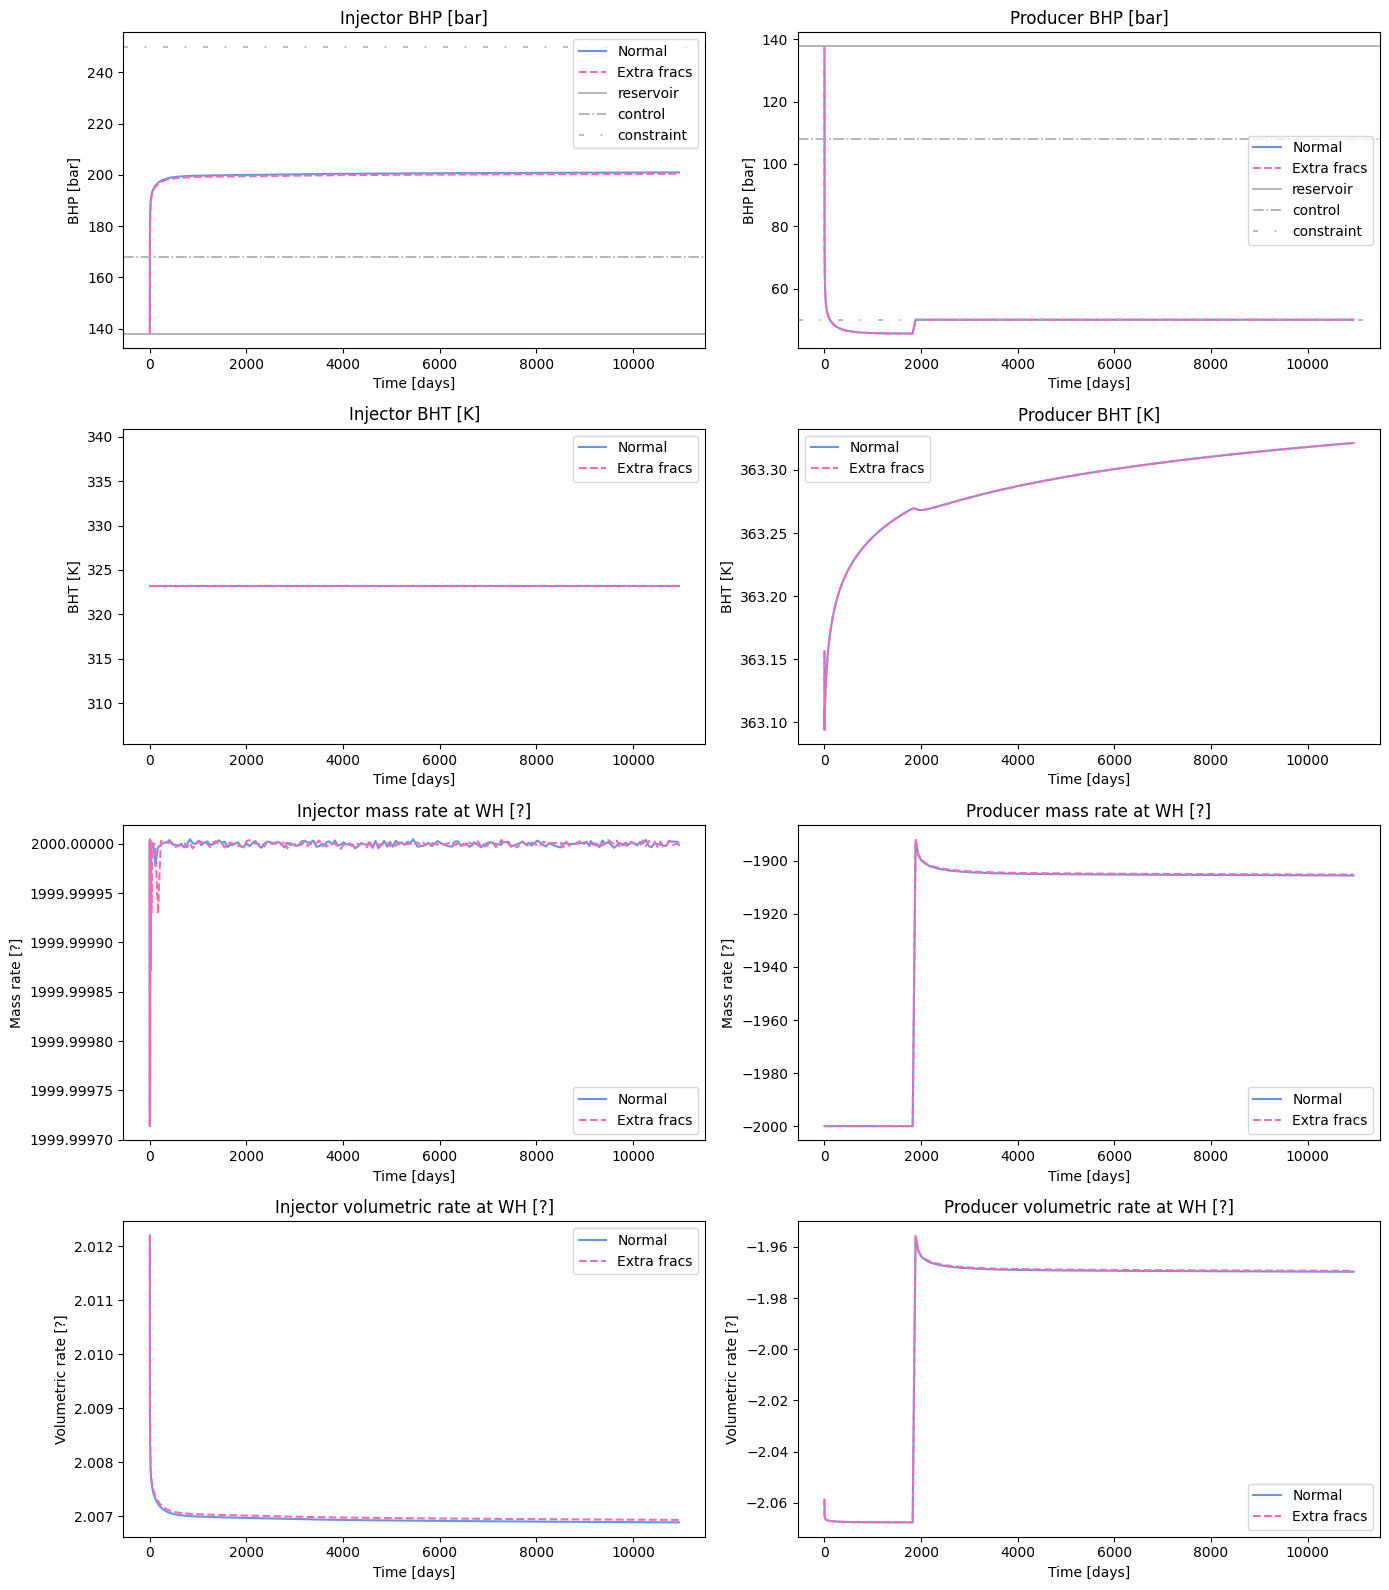

In [ ]:
# Import data 
A1B1C1D1a = os.path.join (base_dir, 'sol_A1B1C1D1_frac_r=2000', 'well_time_data.xlsx')
A1B1C1D1b= os.path.join (base_dir, 'sol_A1B1C1D1_frac_r=2000_noextra', 'well_time_data.xlsx')

# Read excel data 
A1B1C1D1a  = pd.read_excel(A1B1C1D1a)
A1B1C1D1b  = pd.read_excel(A1B1C1D1b)

# Plot results 
plots = [
    ('well_I1_BHP',                     'Injector BHP [bar]',                    'BHP [bar]'),
    ('well_P1_BHP',                     'Producer BHP [bar]',                    'BHP [bar]'),
    ('well_I1_BHT',                     'Injector BHT [K]',                      'BHT [K]'),
    ('well_P1_BHT',                     'Producer BHT [K]',                      'BHT [K]'),
    ('well_I1_mass_rate_L_at_wh',       'Injector mass rate at WH [?]',          'Mass rate [?]'),
    ('well_P1_mass_rate_L_at_wh',       'Producer mass rate at WH [?]',          'Mass rate [?]'),
    ('well_I1_volumetric_rate_L_at_wh', 'Injector volumetric rate at WH [?]',    'Volumetric rate [?]'),
    ('well_P1_volumetric_rate_L_at_wh', 'Producer volumetric rate at WH [?]',    'Volumetric rate [?]'),
]

# Reference lines for the BHP plots: (value [bar], label, linestyle)
loosely_dashdotted = (0, (3, 10, 1, 10))  # (offset, (dash, gap, dot, gap)) in points

ref_lines = {
    'well_I1_BHP': [
        (138, 'reservoir',    '-'),
        (168, 'control',    '-.'),
        (250, 'constraint', loosely_dashdotted),
    ],
    'well_P1_BHP': [
        (138, 'reservoir',    '-'),
        (108, 'control',    '-.'),
        (50,  'constraint', loosely_dashdotted),
    ],
}

plt.rcParams['axes.formatter.useoffset'] = False
fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for ax, (col, title, ylabel) in zip(axes.flatten(), plots):
    ax.plot(A1B1C1D1a['time'], A1B1C1D1a[col],   color='cornflowerblue', label='Normal')
    ax.plot(A1B1C1D1b['time'], A1B1C1D1b[col],   color='hotpink', label='Extra fracs', linestyle='dashed')

    for value, label, ls in ref_lines.get(col, []):
        ax.axhline(value, color='darkgrey', linestyle=ls, linewidth=1.2, label=label)

    ax.set_title(title)
    ax.set_xlabel('Time [days]')
    ax.set_ylabel(ylabel)
    ax.legend()

plt.tight_layout()
plt.show()

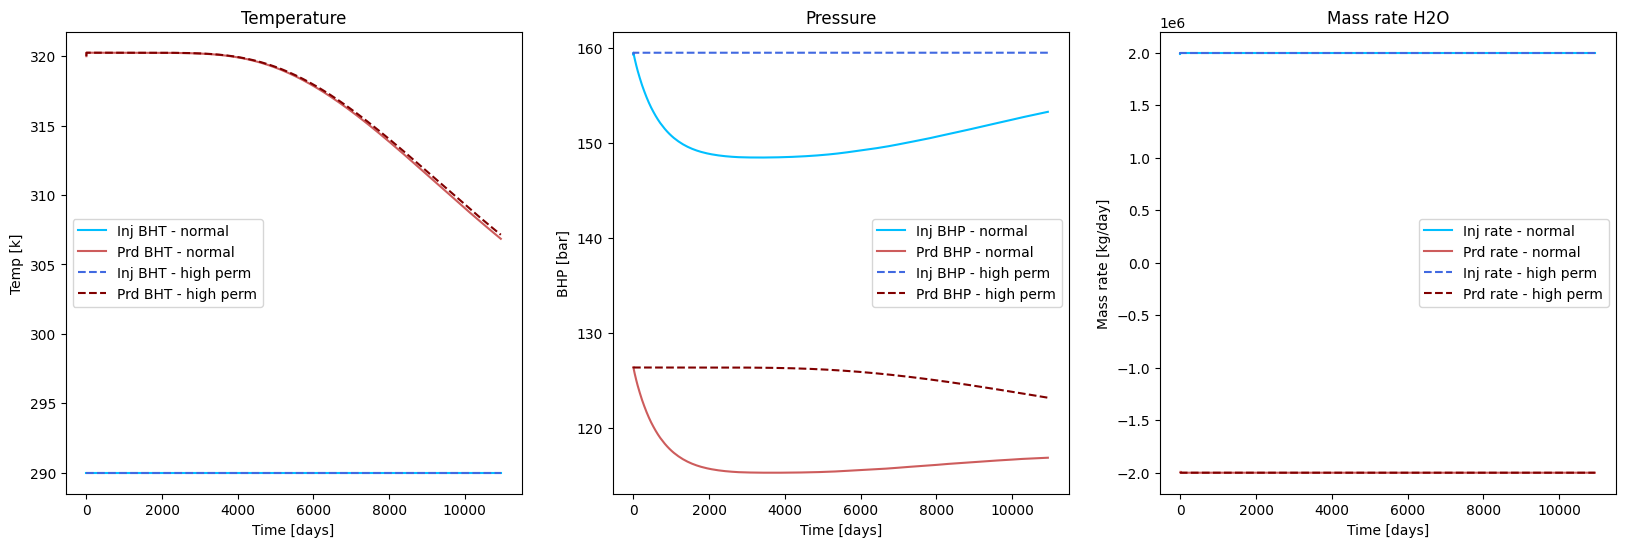

In [4]:
# 30 degree temp difference 
normal = os.path.join (base_dir, 'sol_ORmaxSDplLDmaxAPmax_cell_normal', 'well_time_data.xlsx')
normal = pd.read_excel(normal)

highperm = os.path.join (base_dir, 'sol_ORmaxSDplLDmaxAPmax_cell_highperm', 'well_time_data.xlsx')
highperm = pd.read_excel(highperm)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

ax1.plot (normal['time'], normal['well_I1_BHT'], label='Inj BHT - normal', color='deepskyblue')
ax1.plot (normal['time'], normal['well_P1_BHT'], label='Prd BHT - normal', color='indianred')
ax1.plot (highperm['time'], highperm['well_I1_BHT'], label='Inj BHT - high perm', color='royalblue', linestyle='dashed')
ax1.plot (highperm['time'], highperm['well_P1_BHT'], label='Prd BHT - high perm', color='maroon', linestyle='dashed')
ax1.set_title ('Temperature')
ax1.set_xlabel ('Time [days]')
ax1.set_ylabel ('Temp [k]')
ax1.legend ()

ax2.plot (normal['time'], normal['well_I1_BHP'], label='Inj BHP - normal', color='deepskyblue')
ax2.plot (normal['time'], normal['well_P1_BHP'], label='Prd BHP - normal', color='indianred')
ax2.plot (highperm['time'], highperm['well_I1_BHP'], label='Inj BHP - high perm', color='royalblue', linestyle='dashed')
ax2.plot (highperm['time'], highperm['well_P1_BHP'], label='Prd BHP - high perm', color='maroon', linestyle='dashed')
ax2.set_title ('Pressure')
ax2.set_xlabel ('Time [days]')
ax2.set_ylabel ('BHP [bar]')
ax2.legend ()

ax3.plot (normal['time'], normal['well_I1_mass_rate_H2O_by_sum_perfs'], label='Inj rate - normal', color='deepskyblue')
ax3.plot (normal['time'], normal['well_P1_mass_rate_H2O_by_sum_perfs'], label='Prd rate - normal', color='indianred')
ax3.plot (highperm['time'], highperm['well_I1_mass_rate_H2O_by_sum_perfs'], label='Inj rate - high perm', color='royalblue', linestyle='dashed')
ax3.plot (highperm['time'], highperm['well_P1_mass_rate_H2O_by_sum_perfs'], label='Prd rate - high perm', color='maroon', linestyle='dashed')
ax3.set_title ('Mass rate H2O')
ax3.set_xlabel ('Time [days]')
ax3.set_ylabel ('Mass rate [kg/day]')
ax3.legend ()

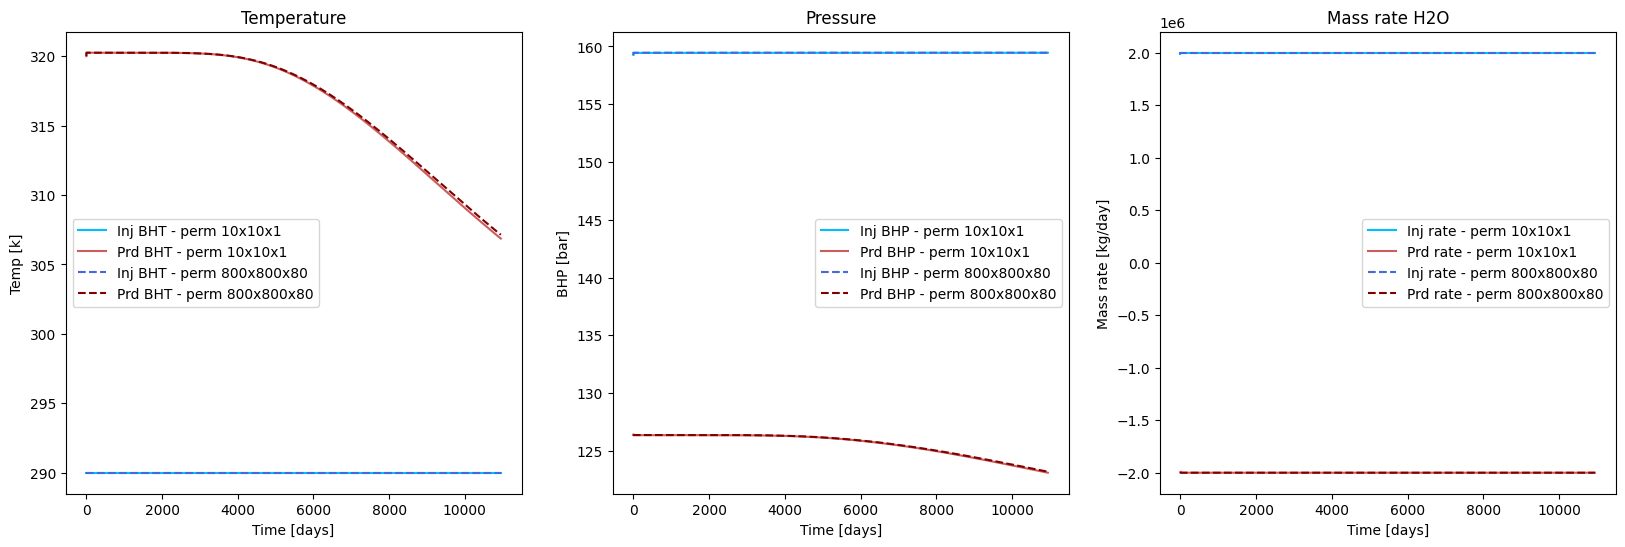

In [8]:
# 1 degree temp difference 
normal = os.path.join (base_dir, 'sol_ORmaxSDplLDmaxAPmax_cell_perm10x10x1', 'well_time_data.xlsx')
normal = pd.read_excel(normal)

highperm = os.path.join (base_dir, 'sol_ORmaxSDplLDmaxAPmax_cell_highperm', 'well_time_data.xlsx')
highperm = pd.read_excel(highperm)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

ax1.plot (normal['time'], normal['well_I1_BHT'], label='Inj BHT - perm 10x10x1', color='deepskyblue')
ax1.plot (normal['time'], normal['well_P1_BHT'], label='Prd BHT - perm 10x10x1', color='indianred')
ax1.plot (highperm['time'], highperm['well_I1_BHT'], label='Inj BHT - perm 800x800x80', color='royalblue', linestyle='dashed')
ax1.plot (highperm['time'], highperm['well_P1_BHT'], label='Prd BHT - perm 800x800x80', color='maroon', linestyle='dashed')
ax1.set_title ('Temperature')
ax1.set_xlabel ('Time [days]')
ax1.set_ylabel ('Temp [k]')
ax1.legend ()

ax2.plot (normal['time'], normal['well_I1_BHP'], label='Inj BHP - perm 10x10x1', color='deepskyblue')
ax2.plot (normal['time'], normal['well_P1_BHP'], label='Prd BHP - perm 10x10x1', color='indianred')
ax2.plot (highperm['time'], highperm['well_I1_BHP'], label='Inj BHP - perm 800x800x80', color='royalblue', linestyle='dashed')
ax2.plot (highperm['time'], highperm['well_P1_BHP'], label='Prd BHP - perm 800x800x80', color='maroon', linestyle='dashed')
ax2.set_title ('Pressure')
ax2.set_xlabel ('Time [days]')
ax2.set_ylabel ('BHP [bar]')
ax2.legend ()

ax3.plot (normal['time'], normal['well_I1_mass_rate_H2O_by_sum_perfs'], label='Inj rate - perm 10x10x1', color='deepskyblue')
ax3.plot (normal['time'], normal['well_P1_mass_rate_H2O_by_sum_perfs'], label='Prd rate - perm 10x10x1', color='indianred')
ax3.plot (highperm['time'], highperm['well_I1_mass_rate_H2O_by_sum_perfs'], label='Inj rate - perm 800x800x80', color='royalblue', linestyle='dashed')
ax3.plot (highperm['time'], highperm['well_P1_mass_rate_H2O_by_sum_perfs'], label='Prd rate - perm 800x800x80', color='maroon', linestyle='dashed')
ax3.set_title ('Mass rate H2O')
ax3.set_xlabel ('Time [days]')
ax3.set_ylabel ('Mass rate [kg/day]')
ax3.legend ()

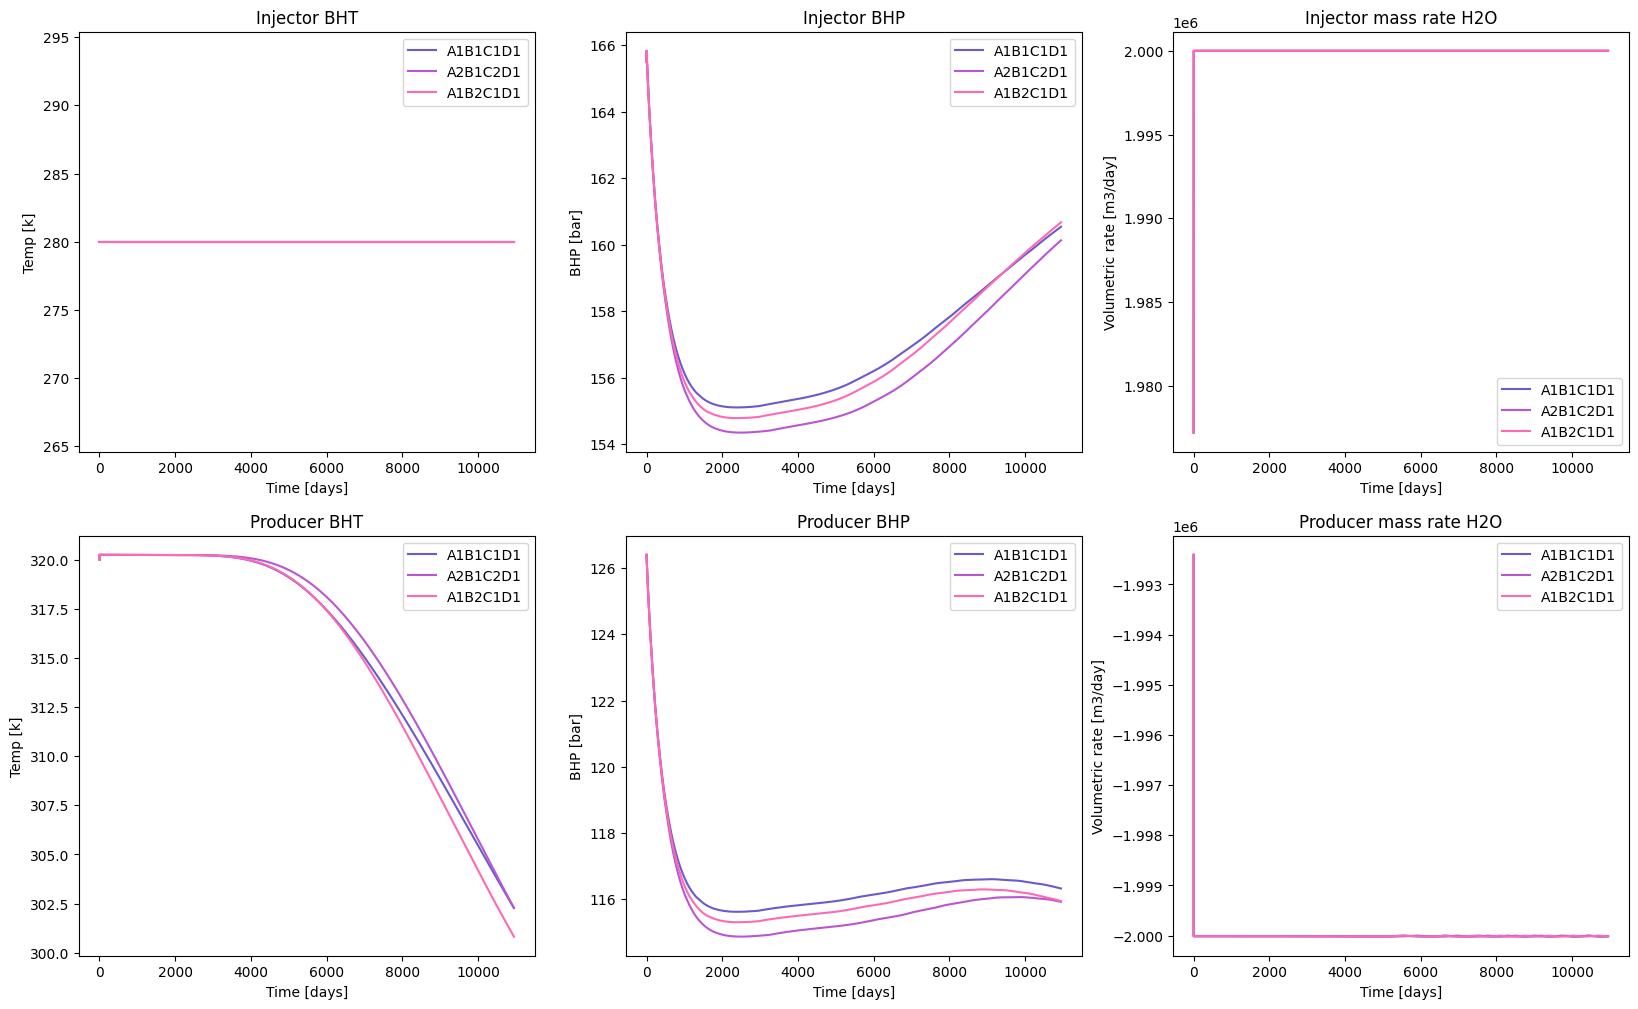

In [5]:
# r2000000, initial perm
A1B1C1D1 = os.path.join (base_dir, 'sol_A1B1C1D1_perm0.01x0.01x1e-5', 'well_time_data.xlsx')
A1B1C1D1 = pd.read_excel(A1B1C1D1)

A2B1C2D1 = os.path.join (base_dir, 'sol_A2B1C2D1', 'well_time_data.xlsx')
A2B1C2D1 = pd.read_excel(A2B1C2D1)

A1B2C1D1 = os.path.join (base_dir, 'sol_A1B2C1D1', 'well_time_data.xlsx')
A1B2C1D1 = pd.read_excel(A1B2C1D1)

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
ax1, ax2, ax3 = axes[0]  
ax4, ax5, ax6 = axes[1]   

ax1.plot (A1B1C1D1['time'], A1B1C1D1['well_I1_BHT'], label='A1B1C1D1', color='slateblue')
ax1.plot (A2B1C2D1['time'], A2B1C2D1['well_I1_BHT'], label='A2B1C2D1', color='mediumorchid')
ax1.plot (A1B2C1D1['time'], A1B2C1D1['well_I1_BHT'], label='A1B2C1D1', color='hotpink')
ax1.set_title ('Injector BHT')
ax1.set_xlabel ('Time [days]')
ax1.set_ylabel ('Temp [k]')
ax1.legend ()

ax2.plot (A1B1C1D1['time'], A1B1C1D1['well_I1_BHP'], label='A1B1C1D1', color='slateblue')
ax2.plot (A2B1C2D1['time'], A2B1C2D1['well_I1_BHP'], label='A2B1C2D1', color='mediumorchid')
ax2.plot (A1B2C1D1['time'], A1B2C1D1['well_I1_BHP'], label='A1B2C1D1', color='hotpink')
ax2.set_title ('Injector BHP')
ax2.set_xlabel ('Time [days]')
ax2.set_ylabel ('BHP [bar]')
ax2.legend ()

ax3.plot (A1B1C1D1['time'], A1B1C1D1['well_I1_mass_rate_H2O_by_sum_perfs'], label='A1B1C1D1', color='slateblue')
ax3.plot (A2B1C2D1['time'], A2B1C2D1['well_I1_mass_rate_H2O_by_sum_perfs'], label='A2B1C2D1', color='mediumorchid')
ax3.plot (A1B2C1D1['time'], A1B2C1D1['well_I1_mass_rate_H2O_by_sum_perfs'], label='A1B2C1D1', color='hotpink')
ax3.set_title ('Injector mass rate H2O')
ax3.set_xlabel ('Time [days]')
ax3.set_ylabel ('Volumetric rate [m3/day]')
ax3.legend ()

ax4.plot (A1B1C1D1['time'], A1B1C1D1['well_P1_BHT'], label='A1B1C1D1', color='slateblue')
ax4.plot (A2B1C2D1['time'], A2B1C2D1['well_P1_BHT'], label='A2B1C2D1', color='mediumorchid')
ax4.plot (A1B2C1D1['time'], A1B2C1D1['well_P1_BHT'], label='A1B2C1D1', color='hotpink')
ax4.set_title ('Producer BHT')
ax4.set_xlabel ('Time [days]')
ax4.set_ylabel ('Temp [k]')
ax4.legend ()

ax5.plot (A1B1C1D1['time'], A1B1C1D1['well_P1_BHP'], label='A1B1C1D1', color='slateblue')
ax5.plot (A2B1C2D1['time'], A2B1C2D1['well_P1_BHP'], label='A2B1C2D1', color='mediumorchid')
ax5.plot (A1B2C1D1['time'], A1B2C1D1['well_P1_BHP'], label='A1B2C1D1', color='hotpink')
ax5.set_title ('Producer BHP')
ax5.set_xlabel ('Time [days]')
ax5.set_ylabel ('BHP [bar]')
ax5.legend ()

ax6.plot (A1B1C1D1['time'], A1B1C1D1['well_P1_mass_rate_H2O_by_sum_perfs'], label='A1B1C1D1', color='slateblue')
ax6.plot (A2B1C2D1['time'], A2B1C2D1['well_P1_mass_rate_H2O_by_sum_perfs'], label='A2B1C2D1', color='mediumorchid')
ax6.plot (A1B2C1D1['time'], A1B2C1D1['well_P1_mass_rate_H2O_by_sum_perfs'], label='A1B2C1D1', color='hotpink')
ax6.set_title ('Producer mass rate H2O')
ax6.set_xlabel ('Time [days]')
ax6.set_ylabel ('Volumetric rate [m3/day]')
ax6.legend ()